# Milestone 2, Part 2: Baseline Conditional Generation

This notebook covers the second Milestone 2 task: **run baseline conditional generation**. It uses the pipeline integrated in Part 1 (`t2i.py`) to generate all 20 Milestone 1 baseline prompts with 3 seeds each, at fixed settings. It then checks that the outputs match their prompts and not just that the model can produce *an* image.

- Every image is saved with a JSON file holding its prompt, seed, sampler, step count, guidance scale, timings, GPU memory and package versions. `manifest.jsonl` lists them all.
- Runs resume: an image whose JSON file exists is skipped, so a Colab disconnect loses nothing.
- Prompt alignment is measured with CLIP ViT-B/32, the Milestone 1 model, which is a different network from the CLIP ViT-L/14 encoder that conditions Stable Diffusion. FID and Inception Score belong to Milestone 3.

Section 3 suggests how to extend this notebook to the guidance, sampler and noise-schedule experiments.

## 1. Setup

In [ ]:
# Find the repo, move into the notebook folder, and pick a device
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/rasmussenj03/IE7615-Group3-Project2.git"
WORK_DIR = "Milestone 2"  # folder holding the notebooks, relative to the repo root
COLAB_USE_DRIVE = True  # False -> clone into /content (outputs are lost when the runtime ends)
COLAB_REPO_DIR = ("/content/drive/MyDrive/IE7615-Group3-Project2" if COLAB_USE_DRIVE
                  else "/content/IE7615-Group3-Project2")

if "google.colab" in sys.modules:
    if COLAB_USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
    if not Path(COLAB_REPO_DIR, "requirements.txt").is_file():
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")  # Colab secret holding a GitHub access token
        clone = subprocess.run(["git", "clone", "-q", REPO_URL.replace("https://", f"https://{token}@"),
                                COLAB_REPO_DIR], capture_output=True)
        if clone.returncode != 0:
            raise RuntimeError("git clone failed - check the GITHUB_TOKEN secret and repo access")
        subprocess.run(["git", "-C", COLAB_REPO_DIR, "remote", "set-url", "origin", REPO_URL])
    root = Path(COLAB_REPO_DIR)
    # Install the pinned packages (local runs use the .venv instead)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements.txt")],
                   check=True)
else:
    root = Path.cwd()
    while not (root / "requirements.txt").exists() and root != root.parent:
        root = root.parent

PROJECT_ROOT = root
os.chdir(PROJECT_ROOT / WORK_DIR)
sys.path.insert(0, str(Path.cwd()))  # t2i.py and lora.py live next to the notebooks

import torch
if torch.cuda.is_available():
    device = "cuda"
    device_name = "cuda - " + torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = device_name = "mps"
else:
    device = device_name = "cpu"
print("Project root:", PROJECT_ROOT)
print("Working folder:", Path.cwd())
print("PyTorch", torch.__version__, "| device:", device_name)

Mounted at /content/drive
Project root: /content/drive/MyDrive/IE7615-Group3-Project2
Working folder: /content/drive/MyDrive/IE7615-Group3-Project2/Milestone 2
PyTorch 2.8.0+cu128 | device: cuda - Tesla T4


In [ ]:
# Imports
import json
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

import t2i

assert device == "cuda" or os.environ.get("M2_ALLOW_CPU"), \
    "This notebook needs a CUDA GPU (set M2_ALLOW_CPU=1 to try anyway; it will be very slow)"

In [ ]:
# Paths and experiment settings
M1_DIR = Path("..") / "Milestone 1"
BASELINE_DIR = M1_DIR / "Project2_Baseline"
with open(BASELINE_DIR / "data" / "baseline_prompts.json", encoding="utf-8") as f:
    baseline = json.load(f)
by_id = {b["prompt_id"]: b for b in baseline}

OUT_DIR = Path("outputs")
GEN_DIR = OUT_DIR / "generated"
FIG_DIR = OUT_DIR / "figures"
LOG_DIR = OUT_DIR / "logs"
for d in (GEN_DIR, FIG_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 4                   # images per UNet batch (x2 with guidance); lower it if CUDA runs out of memory

# Baseline settings (held fixed whenever a sweep varies something else)
BASE = dict(sampler="ddim", steps=50, guidance_scale=7.5)
SEED_OFFSETS = [0, 100, 200]     # seeds = Milestone 1 generation_seed + offset

In [ ]:
# Load the integrated pipeline and the CLIP scorer
c = t2i.load_components(t2i.MODEL_ID, device)
TAG = "base"   # names the output folders; a later fine-tuned run can use "lora"
scorer = t2i.ClipScorer(device=device)
all_prompts = [b["prompt"] for b in baseline]
all_text = scorer.text_embeds(all_prompts)
pidx = {b["prompt_id"]: i for i, b in enumerate(baseline)}

def job(pid, seed_offset=0, **kw):
    b = by_id[pid]
    j = {"prompt_id": pid, "prompt": b["prompt"], "seed": b["generation_seed"] + seed_offset,
         "seed_offset": seed_offset, **BASE, "model_variant": TAG}
    j.update(kw)
    return j

def score(records, out_dir):
    """Attach CLIP score, top-1 retrieval among the 20 prompts, and saturation to each record."""
    imgs = [t2i.load_image(out_dir, r) for r in records]
    emb = scorer.image_embeds(imgs)
    tgt = [pidx[r["prompt_id"]] for r in records]
    sims = emb @ all_text.T
    for r, e, s, i, t in zip(records, emb, sims, imgs, tgt):
        r["clip_score"] = float(100 * s[t])
        r["top1"] = bool(s.argmax().item() == t)
        r["saturation"] = t2i.mean_saturation(i)
        r["_emb"] = e
    return records

print("Pipeline:", c.model_id, "| variant:", TAG, "| dtype:", c.dtype)

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

... (13 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Pipeline: stable-diffusion-v1-5/stable-diffusion-v1-5 | variant: base | dtype: torch.float16


## 2. Baseline conditional generation

All 20 baseline prompts, 3 seeds each, at the baseline settings (DDIM, 50 steps, w = 7.5, 512×512). Each row shows the real COCO photo the caption came from, for reference only. The model never sees it, and matching it exactly is not the goal.

In [ ]:
# Generate 60 baseline images
BASE_DIR = GEN_DIR / f"baseline_{TAG}"
base_jobs = [job(b["prompt_id"], off) for b in baseline for off in SEED_OFFSETS]
t0 = time.perf_counter()
base_records = t2i.run_jobs(c, base_jobs, BASE_DIR, batch_size=BATCH_SIZE, image_format="png")
print(f"Wall time: {(time.perf_counter() - t0) / 60:.1f} min")

  4/60 new | ddim n=50 w=7.5 | 6.31 s/image
  8/60 new | ddim n=50 w=7.5 | 6.18 s/image
  12/60 new | ddim n=50 w=7.5 | 6.35 s/image
  16/60 new | ddim n=50 w=7.5 | 6.41 s/image
  20/60 new | ddim n=50 w=7.5 | 6.54 s/image
  24/60 new | ddim n=50 w=7.5 | 6.86 s/image
  28/60 new | ddim n=50 w=7.5 | 6.80 s/image
  32/60 new | ddim n=50 w=7.5 | 6.67 s/image
  36/60 new | ddim n=50 w=7.5 | 6.77 s/image
  40/60 new | ddim n=50 w=7.5 | 6.79 s/image
  44/60 new | ddim n=50 w=7.5 | 6.72 s/image
  48/60 new | ddim n=50 w=7.5 | 6.75 s/image
  52/60 new | ddim n=50 w=7.5 | 6.78 s/image
  56/60 new | ddim n=50 w=7.5 | 6.76 s/image
  60/60 new | ddim n=50 w=7.5 | 6.78 s/image
60 images in outputs/generated/baseline_base (0 reused)
Wall time: 6.8 min


In [ ]:
# Score, and compare with the real photos
score(base_records, BASE_DIR)
ref_imgs = [Image.open(BASELINE_DIR / b["local_reference_image"]).convert("RGB") for b in baseline]
ref_emb = scorer.image_embeds(ref_imgs)
ref_scores = (100 * (ref_emb * all_text).sum(-1)).numpy()

per_prompt = defaultdict(list)
for r in base_records:
    per_prompt[r["prompt_id"]].append(r)

rows = []
for b, ref_s in zip(baseline, ref_scores):
    rs = per_prompt[b["prompt_id"]]
    emb = torch.stack([r["_emb"] for r in rs])
    rows.append({"prompt_id": b["prompt_id"], "prompt": b["prompt"],
                 "clip_score_mean": float(np.mean([r["clip_score"] for r in rs])),
                 "clip_score_reference_photo": float(ref_s),
                 "top1_rate": float(np.mean([r["top1"] for r in rs])),
                 "seed_diversity": t2i.pairwise_diversity(emb)})

baseline_summary = {
    "settings": {**BASE, "seeds_per_prompt": len(SEED_OFFSETS), "resolution": 512, "variant": TAG},
    "clip_score_mean": float(np.mean([r["clip_score"] for r in base_records])),
    "clip_score_reference_photos": float(ref_scores.mean()),
    "top1_generated": float(np.mean([r["top1"] for r in base_records])),
    "top1_reference_photos": t2i.retrieval_top1(ref_emb, all_text, list(range(len(baseline)))),
    "sec_per_image": float(np.mean([r["timings"]["per_image_s"] for r in base_records])),
    "peak_memory_mb": max((r["peak_memory_mb"] or 0) for r in base_records),
    "per_prompt": rows,
}
t2i.write_json(LOG_DIR / f"baseline_{TAG}_summary.json", baseline_summary)

print(f"CLIP score: generated {baseline_summary['clip_score_mean']:.1f} vs real photos {baseline_summary['clip_score_reference_photos']:.1f}")
print(f"Top-1 among 20 prompts: generated {baseline_summary['top1_generated']:.0%} vs real photos "
      f"{baseline_summary['top1_reference_photos']:.0%} (chance 5%)")
print(f"{baseline_summary['sec_per_image']:.2f} s/image (batch {BATCH_SIZE}) | peak GPU memory {baseline_summary['peak_memory_mb']} MB\n")
for r in rows:
    print(f"{r['prompt_id']}  gen {r['clip_score_mean']:5.1f} | photo {r['clip_score_reference_photo']:5.1f} | "
          f"top-1 {r['top1_rate']:4.0%} | {r['prompt'][:60]}")

CLIP score: generated 32.1 vs real photos 30.5
Top-1 among 20 prompts: generated 100% vs real photos 95% (chance 5%)
6.63 s/image (batch 4) | peak GPU memory 5080.9 MB

prompt_01  gen  31.4 | photo  31.1 | top-1 100% | there is a large book shelf in this living room
prompt_02  gen  32.8 | photo  28.7 | top-1 100% | A man riding on the back of a brown horse through a lush gre
prompt_03  gen  30.5 | photo  30.4 | top-1 100% | A hot dog with sour kraut on a plate.
prompt_04  gen  30.1 | photo  30.0 | top-1 100% | there is various healthy vegetables on a plate
prompt_05  gen  27.5 | photo  24.8 | top-1 100% | A house is empty with no one in it.
prompt_06  gen  34.7 | photo  32.9 | top-1 100% | A gray cat laying on top of a wooden book shelf.
prompt_07  gen  30.5 | photo  25.8 | top-1 100% | A MAN IS PLAYING ON THE BEACH WITH A FRIEND
prompt_08  gen  38.8 | photo  34.7 | top-1 100% | A green truck cake sitting on top of a table.
prompt_09  gen  32.6 | photo  31.0 | top-1 100% | A red double

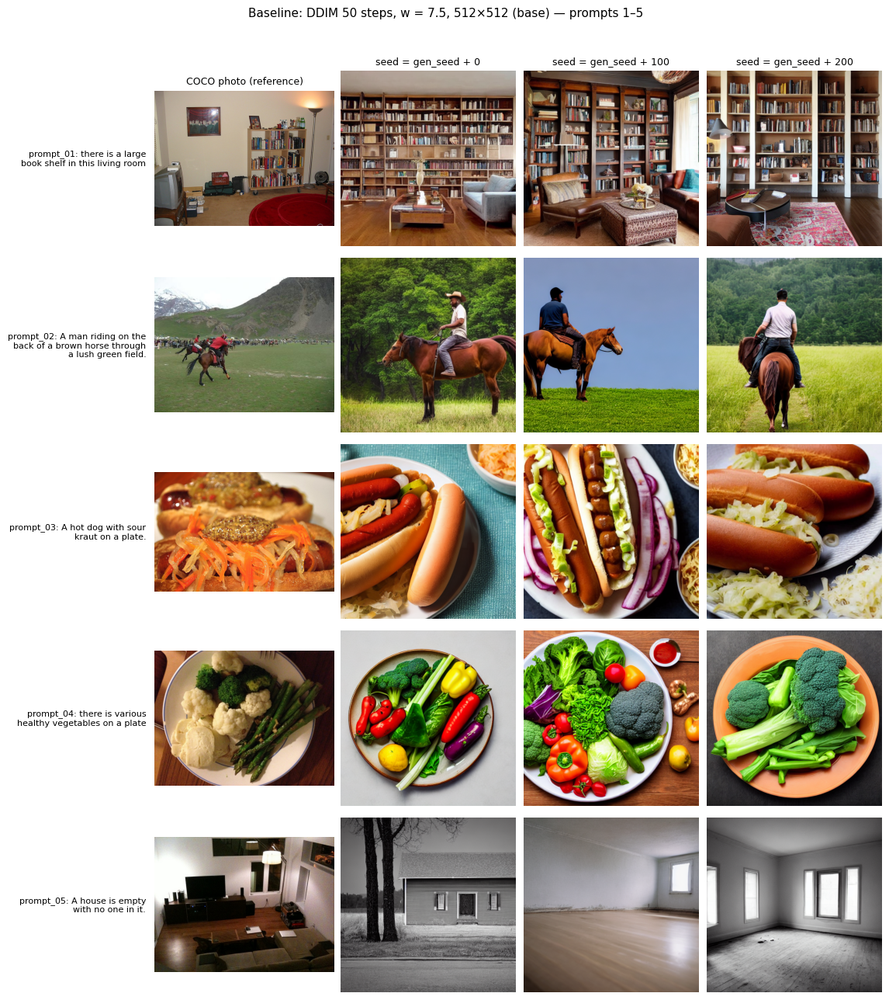

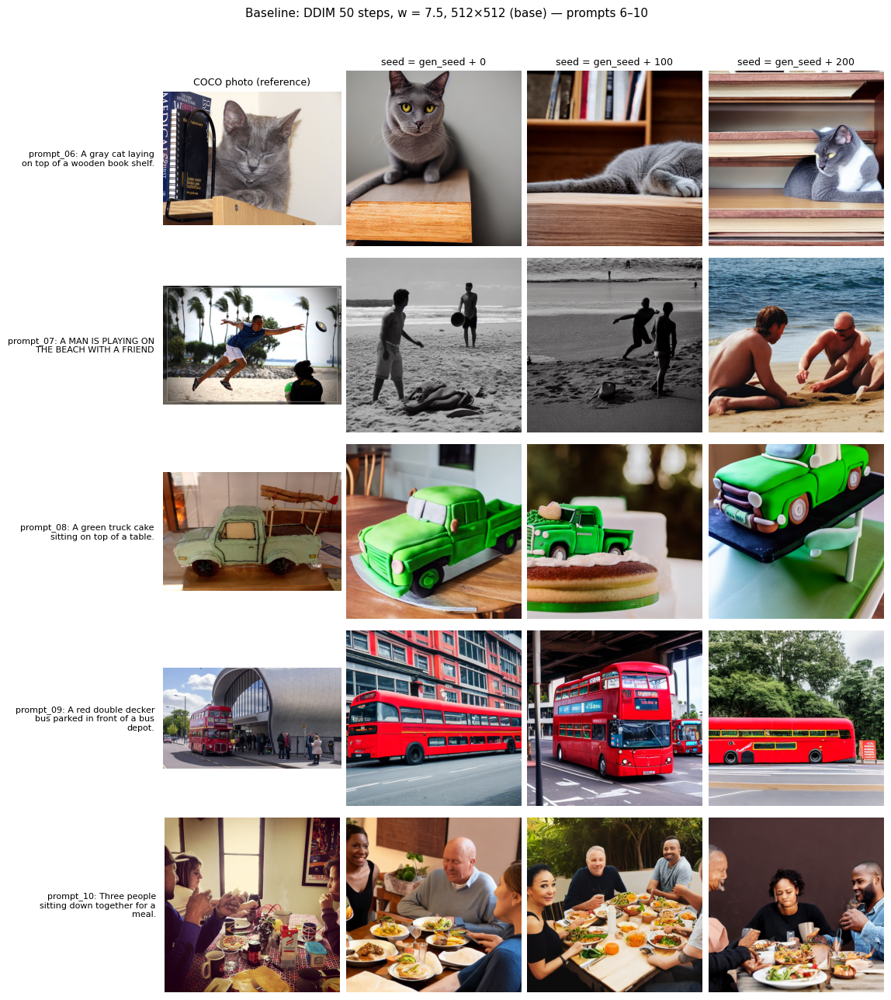

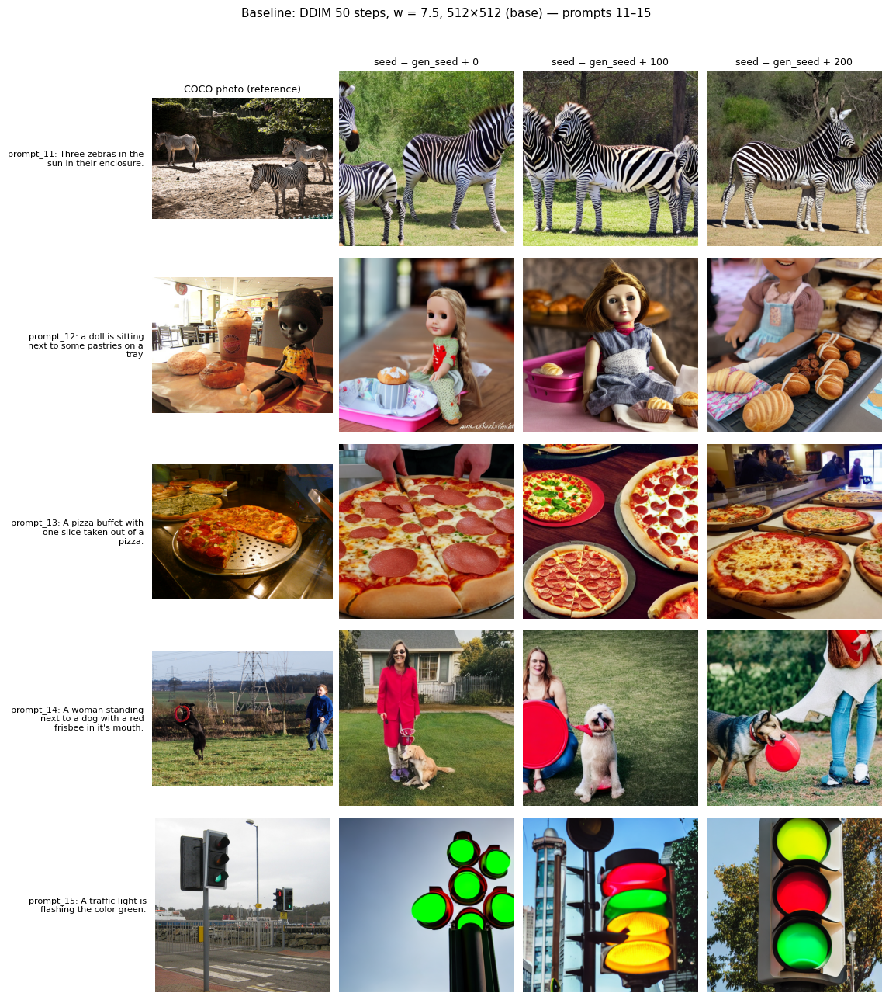

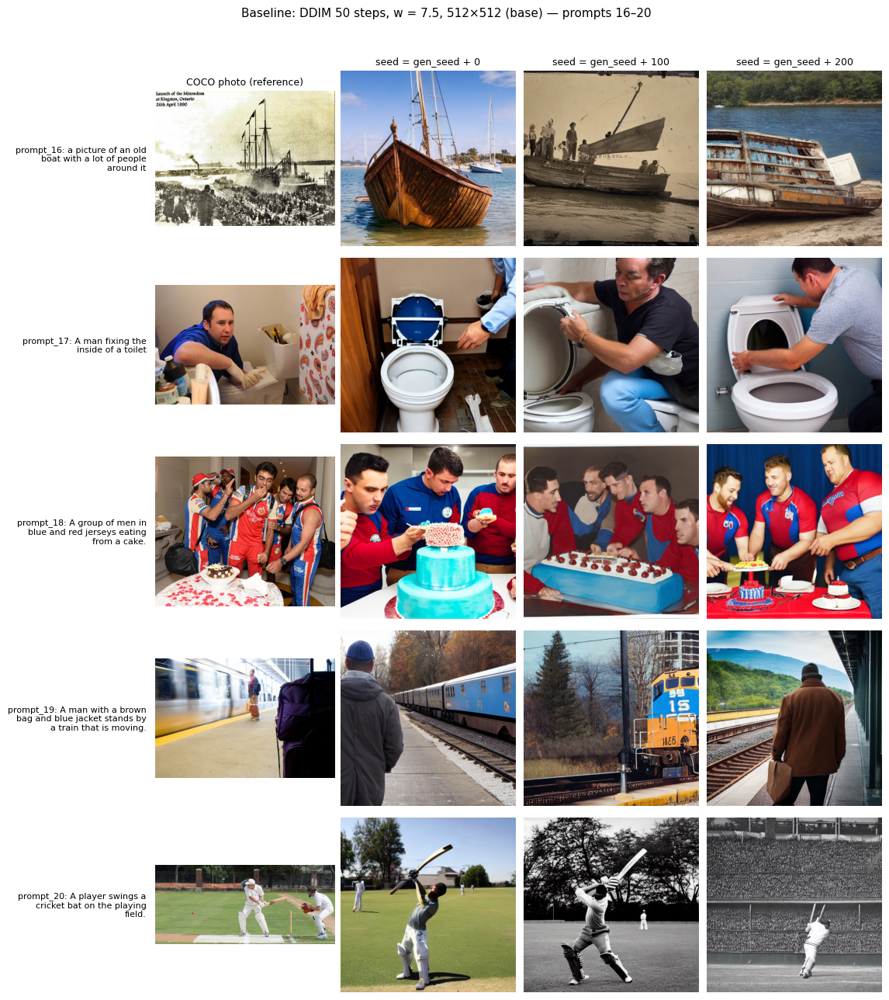

In [ ]:
# Baseline gallery: 5 prompts per figure, reference photo + 3 seeds
for page in range(4):
    chunk = baseline[page * 5:(page + 1) * 5]
    grid, labels = [], []
    for b in chunk:
        rs = sorted(per_prompt[b["prompt_id"]], key=lambda r: r["seed"])
        grid.append([Image.open(BASELINE_DIR / b["local_reference_image"]).convert("RGB")] +
                    [t2i.load_image(BASE_DIR, r) for r in rs])
        labels.append(f"{b['prompt_id']}: {b['prompt']}")
    seeds_txt = ["COCO photo (reference)"] + [f"seed = gen_seed + {o}" for o in SEED_OFFSETS]
    fig = t2i.labeled_grid(grid, labels, seeds_txt, cell=2.5, row_label_width=30,
                           title=f"Baseline: DDIM 50 steps, w = 7.5, 512×512 ({TAG}) — prompts {page * 5 + 1}–{page * 5 + 5}")
    fig.savefig(FIG_DIR / f"20_baseline_{TAG}_{page + 1}.png", dpi=110, bbox_inches="tight")
    plt.show()

**Observations (TODO after the run):**

## 3. Next steps: extending this notebook

The baseline above fixes every setting (DDIM, 50 steps, w = 7.5). The remaining tasks vary one setting at a time on the same prompts and seeds, so their outputs can be compared directly with this baseline. Each experiment is a list of jobs passed to `t2i.run_jobs`, which batches, saves, skips finished images and writes a manifest. `job(pid, seed_offset, **overrides)` and `score(records, out_dir)` from Section 1 are reused unchanged.

Use a subset of about 6 varied prompts to keep the cost down, for example `["prompt_01", "prompt_02", "prompt_03", "prompt_09", "prompt_11", "prompt_14"]`: a scene, an animal with attributes, food, a colored vehicle, counting, and a multi-object relation.

### 3.1 Guidance-scale sweep (Task 3, "Parameter Tuning", 20 pts)
- Jobs: `job(pid, off, guidance_scale=w)` for w in `[0, 1, 3, 5, 7.5, 10, 15]`. That is 7 settings, more than the 3 the spec requires, and includes w = 0 (unconditional) and w = 1 (no guidance).
- Per w, report:
  - mean CLIP score and top-1 retrieval (alignment);
  - `t2i.pairwise_diversity` over the 3 seeds of each prompt (diversity);
  - `t2i.mean_saturation` (the over-saturated look of high guidance);
  - seconds per image. At w = 1 the unconditional pass is skipped, so it costs about half.
- Figures: the metrics against w, a prompts × w grid for one seed, and a seeds × {1, 7.5, 15} grid for diversity.

### 3.2 Samplers and step counts (Task 4, quality vs compute)
- Jobs: `job(pid, sampler=s, steps=n)` for s in `t2i.SAMPLERS` (DDPM, DDIM, PNDM, Euler, Euler-a, DPM++ 2M, DPM++ 2M Karras) and n in `[10, 20, 50]`.
- Add a near-converged reference with `job(pid, sampler="dpmpp_2m", steps=100, variant="reference")`. The deterministic samplers all solve the same ODE, so `t2i.psnr` and CLIP-image similarity to the reference measure convergence.
- The stochastic samplers (`t2i.STOCHASTIC_SAMPLERS`) converge to different images, so judge them by CLIP score and by eye.
- Plot quality against seconds per image.

### 3.3 Noise schedule (Task 4)
SD 1.5's β schedule is fixed by training, so vary how the sampler moves through it. Pass these as `scheduler_overrides` with a unique `variant`:
- timestep spacing for DDIM at 10 and 20 steps: `{"timestep_spacing": "leading" | "trailing" | "linspace"}`;
- Karras σ spacing: `dpmpp_2m` vs `dpmpp_2m_karras`, from 3.2;
- a deliberate train/inference mismatch: `{"beta_schedule": "linear"}` or `{"beta_schedule": "squaredcos_cap_v2"}`. This should degrade the images and shows the schedule is learned into the weights.

### 3.4 Fine-tuned variant
After the Part 1 cross-attention fine-tune, call `lora.load_lora(c.unet, OUT_DIR / "lora_run" / "lora", dtype=c.dtype)`, set `TAG = "lora"` and re-run Section 2. Outputs land in separate folders, so base and fine-tuned results can be compared prompt by prompt.

### 3.5 Samples gallery and summary (Task 5 deliverables)
- Save every comparison figure to `outputs/figures/` with prompts and settings in its labels, then join them into one PDF.
- Write each experiment's metrics table to `outputs/logs/*.json`, as Section 2 does with `baseline_base_summary.json`, and copy the numbers into `docs/training_logs_summary.md`.